# Notebook 04 — Module 4: Exploratory analysis and statistical testing with spatial null models
**Input:** `features_cell_level.parquet` and `src/spatialml` from Notebook 03.
**Question:** do spatial features differ across the microenvironment classes, and is that more than spatial autocorrelation alone would produce?

**Why this notebook is not "just run a Kruskal–Wallis test"**
With 160k spatially dependent cells, a naive test gives p ≈ 0 for almost any feature, because neighboring cells are not independent. So every claim here uses three layers:

1. **Effect size** (rank η² and one-vs-rest AUC), not p-values alone.
2. **Block bootstrap** confidence intervals (resampling 500 µm tissue blocks, not cells).
3. **Spatial null models**: a toroidal-shift null for feature–class association, and two label-permutation nulls (global vs within-tile) for cell-type neighborhood enrichment.

**Order:** 0 Setup · 1 Data · 2 Target reliability · 3 Stats machinery + unit tests · 4 Effect sizes + bootstrap · 5 Spatial null · 6 Controls by own cell type · 7 Neighborhood enrichment · 8 Save

In [1]:
import os, json, warnings, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial import cKDTree
from scipy.stats import kruskal, chi2
from sklearn.metrics import roc_auc_score, silhouette_samples
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*bottleneck.*")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")
except ImportError:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./spatial_ml_breast_cancer"))

for sub in ["results/figures", "results/tables", "reports", "src/spatialml"]:
    (PROJECT_DIR / sub).mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, REP_DIR, PROC_DIR = (PROJECT_DIR / p for p in ["results/figures", "results/tables", "reports", "data/processed"])
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = json.load(open(PROJECT_DIR / "configs/config.json"))
SEED = CONFIG["seed"]; RNG = np.random.default_rng(SEED)
TD = CONFIG["target_design"]
CONFIG.setdefault("notebook04", {
    "n_bootstrap": 1000, "n_shift_null": 199, "n_label_permutations": 200,
    "null_tile_um": 250, "shift_min_um": 1000, "shift_max_assign_um": 30,
    "min_effect_eta2": 0.01, "medium_effect_eta2": 0.06, "fdr_alpha": 0.05,
    "enrichment_radii_um": [15, 30], "conditional_min_cells": 3000, "conditional_bootstrap": 300,
})
N4 = CONFIG["notebook04"]

Mounted at /content/drive


In [2]:
SRC = r'''"""spatialml.stats - rank-based effect sizes, block bootstrap and spatial null models (Module 4)."""
import numpy as np
import scipy.sparse as sp
from scipy.spatial import cKDTree


def rank_matrix(df):
    """Per-column percentile ranks (rank / n_valid, ties averaged). Returns P (float64, NaN->0) and mask M (1 = observed).
    float64 matters: eta-squared is a small difference of large sums, so float32 ranks lose precision."""
    P = df.rank(method="average", pct=True)
    M = P.notna().to_numpy(np.float32)
    return P.fillna(0.0).to_numpy(np.float64), M


def group_sums(P, M, lab, K, group=None, n_groups=1):
    """Sums of ranks per (group, class, feature). lab = class index (-1 = excluded); group = e.g. spatial block."""
    n = len(lab)
    idx = np.where(lab >= 0)[0]
    g = np.zeros(n, np.int64) if group is None else np.asarray(group, np.int64)
    rows = g[idx] * K + lab[idx]
    Y = sp.csr_matrix((np.ones(len(idx)), (rows, idx)), shape=(n_groups * K, n))
    S = np.asarray(Y @ P, dtype=np.float64).reshape(n_groups, K, -1)
    N = np.asarray(Y @ M, dtype=np.float64).reshape(n_groups, K, -1)
    Wg = sp.csr_matrix((np.ones(len(idx)), (g[idx], idx)), shape=(n_groups, n))
    Q = np.asarray(Wg @ (P.astype(np.float64) ** 2))
    return S, N, Q


def eta2_from_sums(S, N, Q):
    """Rank eta-squared (= Kruskal-Wallis H / (N-1)). Leading axes are broadcast (e.g. bootstrap replicates)."""
    St, Nt = S.sum(-2), N.sum(-2)
    with np.errstate(divide="ignore", invalid="ignore"):
        ssb = (S ** 2 / np.where(N > 0, N, np.inf)).sum(-2) - St ** 2 / Nt
        sst = Q - St ** 2 / Nt
        return ssb / sst


def auc_from_sums(S, N):
    """One-vs-rest AUC per class: P(feature value of a class-c cell > a cell outside c)."""
    St, Nt = S.sum(-2, keepdims=True), N.sum(-2, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        mean_c = S / np.where(N > 0, N, np.nan)
        rest = (St - S) / np.where(Nt - N > 0, Nt - N, np.nan)
    return 0.5 + mean_c - rest


def block_bootstrap(S_b, N_b, Q_b, n_boot, rng):
    """Resample spatial blocks with replacement. Inputs have a leading block axis."""
    nb = S_b.shape[0]
    W = rng.multinomial(nb, np.full(nb, 1.0 / nb), size=n_boot).astype(np.float64)
    S = np.einsum("rb,bkp->rkp", W, S_b)
    N = np.einsum("rb,bkp->rkp", W, N_b)
    Q = W @ Q_b
    return eta2_from_sums(S, N, Q), auc_from_sums(S, N)


def shift_null_labels(xy, lab, rng, min_shift_um=1000.0, max_assign_um=30.0):
    """Toroidal-shift null: slide the label map over the tissue by a random vector (wrapping at the bounding box).
    Preserves the spatial autocorrelation of labels and features, breaks their cross-association."""
    mn = xy.min(0); ext = xy.max(0) - mn
    for _ in range(1000):
        s = rng.uniform(0, 1, 2) * ext
        if np.hypot(*s) >= min_shift_um: break
    shifted = (xy - mn + s) % ext + mn
    v = lab >= 0
    d, j = cKDTree(shifted[v]).query(xy, k=1, workers=-1)
    return np.where(d <= max_assign_um, lab[v][j], -1)


def benjamini_hochberg(p):
    p = np.asarray(p, float); n = len(p)
    o = np.argsort(p); q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1.0)
    return out


def within_group_permutation(codes, group, rng):
    """Shuffle labels only inside each group (e.g. spatial tile): keeps regional composition."""
    order = np.lexsort((rng.random(len(codes)), group))
    base = np.argsort(group, kind="stable")
    out = np.empty_like(codes)
    out[base] = codes[order]
    return out


def pair_counts(ci, cj, T):
    """Counts of unordered type pairs; returns a (T, T) matrix filled on the upper triangle."""
    lo, hi = np.minimum(ci, cj), np.maximum(ci, cj)
    return np.bincount(lo * T + hi, minlength=T * T).reshape(T, T)
'''

assert (PROJECT_DIR / "src/spatialml/neighborhood.py").exists(), "Run Notebook 03 first (it creates src/spatialml/neighborhood.py)."
(PROJECT_DIR / "src/spatialml/stats.py").write_text(SRC)
(PROJECT_DIR / "src/spatialml/__init__.py").write_text("from .neighborhood import *\nfrom .stats import *\n")
sys.path.insert(0, str(PROJECT_DIR / "src"))
import spatialml.neighborhood as nbh
import spatialml.stats as st
importlib.reload(nbh); importlib.reload(st)
print("spatialml.stats written to", PROJECT_DIR / "src/spatialml/stats.py")

spatialml.stats written to /content/drive/MyDrive/spatial_ml_breast_cancer/src/spatialml/stats.py


## Part 1 — Load the feature table and define the analysis cohort

In [3]:
pq = PROC_DIR / "features_cell_level.parquet"
T = pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / "features_cell_level.csv.gz", index_col=0)
meta = pd.read_csv(TAB_DIR / "feature_dictionary.csv")
FEATURES = meta["feature"].tolist()
GROUP = dict(zip(meta["feature"], meta["group"]))
assert all(f in T.columns for f in FEATURES)

xy = T[["x", "y"]].to_numpy(dtype=np.float64)
valid = T["target_valid"].astype(bool).to_numpy()
CLASSES = sorted(T.loc[valid, "microenvironment_class"].unique())
K = len(CLASSES); cls_idx = {c: i for i, c in enumerate(CLASSES)}
lab = np.where(valid, T["microenvironment_class"].map(cls_idx).fillna(-1).astype(int).to_numpy(), -1)

print(f"cells: {len(T):,} | valid target: {valid.sum():,} | classes: {CLASSES}")
print("Features per group:", meta.groupby("group").size().to_dict())
print("Missingness (valid cells), top:", T.loc[valid, FEATURES].isna().mean().sort_values(ascending=False).head(3).round(3).to_dict())

cells: 164,000 | valid target: 163,122 | classes: ['ME1_Epithelial-rich', 'ME2_Epithelial/T_cell', 'ME3_T_cell/Stromal']
Features per group: {'boundary': 2, 'composition': 18, 'density': 4, 'distance': 12, 'diversity': 4, 'morphology': 3}
Missingness (valid cells), top: {'entropy_r15': 0.1, 'dominant_frac_r15': 0.1, 'frac_Epithelial_r15': 0.1}


## Part 2 — How reliable is the target? (continuum check)
Notebook 03 found low silhouette values (≈0.34 at k = 3): microenvironments here behave like a **gradient**, not sharply separated clusters. We quantify that rather than ignore it, and save a continuous version of the target (annulus composition) plus a per-cell **margin** so that Notebooks 05–06 can run sensitivity analyses that drop boundary cells.

Nearest-centroid assignment reproduces the Notebook 03 labels for 99.9% of cells (reproducibility check).


,n,median_silhouette,frac_silhouette_below_0,median_margin
class,,,,
ME1_Epithelial-rich,8588,0.488,0.000,0.408
ME2_Epithelial/T_cell,5815,0.277,0.067,0.246
ME3_T_cell/Stromal,5597,0.307,0.057,0.300


10% lowest-margin cells have margin < 0.087 (flagged as `target_low_margin` for sensitivity analyses).


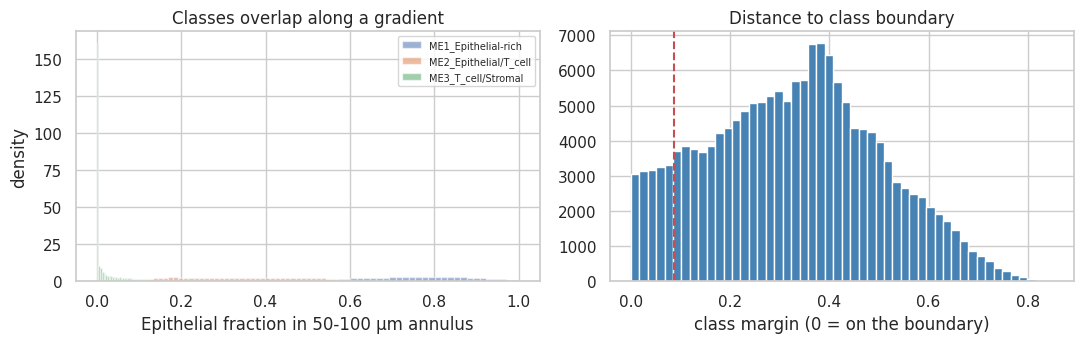

In [4]:
TYPES = ["Epithelial", "T_cell", "B_cell", "Myeloid", "Mast_cell", "Endothelial", "Mural", "Stromal"]
ALL_TYPES = TYPES + ["Unassigned"]
codes = T["cell_type"].map({t: i for i, t in enumerate(ALL_TYPES)}).to_numpy()
onehot = np.eye(len(ALL_TYPES), dtype=np.float32)[codes]
ta = tuple(TD["target_annulus_um"])

ann = nbh.ring_stats(xy, onehot, [ta])[ta]
cnt = ann["counts"]; n_asg = cnt[:, :-1].sum(1)
with np.errstate(divide="ignore", invalid="ignore"):
    frac = cnt[:, :-1] / n_asg[:, None]
frac[~valid] = np.nan
Hm = np.sqrt(np.nan_to_num(frac))

# Class centroids in Hellinger space (= k-means centroids) -> margin to the second-closest centroid
cent = np.vstack([Hm[lab == k].mean(0) for k in range(K)])
D = np.sqrt(((Hm[:, None, :] - cent[None, :, :]) ** 2).sum(2))
order = np.argsort(D, axis=1)
d1 = D[np.arange(len(D)), order[:, 0]]; d2 = D[np.arange(len(D)), order[:, 1]]
margin = np.where(valid, (d2 - d1) / (d2 + d1 + 1e-12), np.nan)
reproduced = (order[valid, 0] == lab[valid]).mean()
print(f"Nearest-centroid assignment reproduces the Notebook 03 labels for {reproduced:.1%} of cells (reproducibility check).")

vidx = np.where(valid)[0]
sub = RNG.choice(vidx, min(20000, len(vidx)), replace=False)
sil = silhouette_samples(Hm[sub], lab[sub])
rel = pd.DataFrame({"class": [CLASSES[k] for k in lab[sub]], "silhouette": sil, "margin": margin[sub]})
rel_tab = rel.groupby("class").agg(n=("silhouette", "size"), median_silhouette=("silhouette", "median"),
                                   frac_silhouette_below_0=("silhouette", lambda s: (s < 0).mean()),
                                   median_margin=("margin", "median"))
display(rel_tab.round(3)); rel_tab.round(4).to_csv(TAB_DIR / "target_reliability.csv")
low_margin_cut = np.nanquantile(margin, 0.10)
print(f"10% lowest-margin cells have margin < {low_margin_cut:.3f} (flagged as `target_low_margin` for sensitivity analyses).")

ann_df = pd.DataFrame(frac, columns=[f"ann_frac_{t}" for t in TYPES], index=T.index)
ann_df["ann_n_cells"] = ann["n"]
ann_df["target_margin"] = margin
ann_df["target_low_margin"] = margin < low_margin_cut
ann_df.to_parquet(PROC_DIR / "target_annulus_composition.parquet") if pq.exists() else ann_df.to_csv(PROC_DIR / "target_annulus_composition.csv.gz")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k in range(K):
    axes[0].hist(frac[lab == k, 0], bins=50, alpha=0.55, label=CLASSES[k], density=True)
axes[0].set_xlabel("Epithelial fraction in 50-100 µm annulus"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=7)
axes[0].set_title("Classes overlap along a gradient")
axes[1].hist(margin[valid], bins=50, color="steelblue"); axes[1].axvline(low_margin_cut, color="C3", ls="--")
axes[1].set_xlabel("class margin (0 = on the boundary)"); axes[1].set_title("Distance to class boundary")
plt.tight_layout(); fig.savefig(FIG_DIR / "target_continuum.png", dpi=200); plt.show()

## Part 3 — Statistical machinery and unit tests
Effect size is the **rank η²** (identical to Kruskal–Wallis H/(N−1)) and the **one-vs-rest AUC** per class. Both are computed from sums of ranks per (block, class, feature), which makes block bootstrap and permutation nulls fast. The tests below check the implementation against SciPy and scikit-learn.

In [5]:
# Unit tests against reference implementations (random subset, includes ties and NaN)
sel = RNG.choice(vidx, min(6000, len(vidx)), replace=False)
feats_test = ["frac_Epithelial_r30", "entropy_r30", "dist_nearest_T_cell", "cell_area"]
P_t, M_t = st.rank_matrix(T.iloc[sel][feats_test])
S, N, Q = st.group_sums(P_t, M_t, lab[sel], K)
eta = st.eta2_from_sums(S[0], N[0], Q[0]); auc = st.auc_from_sums(S[0], N[0])

for j, f in enumerate(feats_test):
    x = T.iloc[sel][f].to_numpy(dtype=np.float64); y = lab[sel]; ok = ~np.isnan(x)   # float64: SciPy keeps float32 inputs in float32
    H = kruskal(*[x[ok & (y == k)] for k in range(K)]).statistic
    assert np.isclose(eta[j], H / (ok.sum() - 1), rtol=1e-6), (f, eta[j], H / (ok.sum() - 1))
    for k in range(K):
        ref = roc_auc_score((y[ok] == k).astype(int), x[ok])
        assert np.isclose(auc[k, j], ref, atol=1e-6), (f, k, auc[k, j], ref)
print("PASS: rank eta-squared == Kruskal-Wallis H/(N-1); one-vs-rest AUC == sklearn roc_auc_score (4 features, all classes).")

# within-group permutation keeps each group's label counts
g = RNG.integers(0, 20, 5000); c0 = RNG.integers(0, 4, 5000); c1 = st.within_group_permutation(c0, g, RNG)
for gg in range(20):
    assert np.array_equal(np.bincount(c0[g == gg], minlength=4), np.bincount(c1[g == gg], minlength=4))
assert (c0 != c1).mean() > 0.3
print("PASS: within-tile permutation preserves per-tile label counts and actually shuffles labels.")

PASS: rank eta-squared == Kruskal-Wallis H/(N-1); one-vs-rest AUC == sklearn roc_auc_score (4 features, all classes).
PASS: within-tile permutation preserves per-tile label counts and actually shuffles labels.


## Part 4 — Observed effect sizes with block-bootstrap confidence intervals

In [6]:
Fv = T.loc[valid, FEATURES]
P, M = st.rank_matrix(Fv)
lab_v = lab[valid]; xy_v = xy[valid]
blk_codes, blk_uni = pd.factorize(T.loc[valid, "spatial_block"])
nb = len(blk_uni); print(f"Spatial blocks (500 µm): {nb}  | median cells/block: {int(np.median(np.bincount(blk_codes)))}")

S_b, N_b, Q_b = st.group_sums(P, M, lab_v, K, group=blk_codes, n_groups=nb)
S_tot, N_tot, Q_tot = S_b.sum(0), N_b.sum(0), Q_b.sum(0)
eta_obs = st.eta2_from_sums(S_tot, N_tot, Q_tot)               # (p,)
auc_obs = st.auc_from_sums(S_tot, N_tot)                        # (K, p)
eta_bs, auc_bs = st.block_bootstrap(S_b, N_b, Q_b, N4["n_bootstrap"], RNG)
eta_lo, eta_hi = np.nanpercentile(eta_bs, [2.5, 97.5], axis=0)
auc_lo, auc_hi = np.nanpercentile(auc_bs, [2.5, 97.5], axis=0)

Ntot = N_tot.sum(0)
H = (Ntot - 1) * eta_obs
naive_p = chi2.sf(H, K - 1)

res = pd.DataFrame({"feature": FEATURES, "group": [GROUP[f] for f in FEATURES], "n_cells": Ntot.astype(int),
                    "eta2": eta_obs, "eta2_ci_low": eta_lo, "eta2_ci_high": eta_hi, "naive_KW_p": naive_p})
for k, c in enumerate(CLASSES):
    res[f"AUC_{c}"] = auc_obs[k]; res[f"AUC_{c}_lo"] = auc_lo[k]; res[f"AUC_{c}_hi"] = auc_hi[k]
print(f"Naive Kruskal-Wallis: {(naive_p < 1e-6).sum()}/{len(res)} features have p < 1e-6 -> p-values alone cannot discriminate features.")
display(res.sort_values("eta2", ascending=False)[["feature", "group", "eta2", "eta2_ci_low", "eta2_ci_high", "naive_KW_p"]].head(15).round(4))

Spatial blocks (500 µm): 176  | median cells/block: 932
Naive Kruskal-Wallis: 43/43 features have p < 1e-6 -> p-values alone cannot discriminate features.


,feature,group,eta2,eta2_ci_low,eta2_ci_high,naive_KW_p
17,frac_Epithelial_r30,composition,0.6518,0.6198,0.6793,0.0
32,dist_nearest_Epithelial,distance,0.6130,0.5791,0.6458,0.0
2,frac_Epithelial_r15,composition,0.5255,0.4844,0.5612,0.0
34,dist_nearest_B_cell,distance,0.4436,0.3793,0.5030,0.0
24,frac_Stromal_r30,composition,0.3381,0.2865,0.3858,0.0
39,dist_nearest_Stromal,distance,0.3139,0.2709,0.3539,0.0
18,frac_T_cell_r30,composition,0.2882,0.2445,0.3348,0.0
3,frac_T_cell_r15,composition,0.2675,0.2240,0.3078,0.0
19,frac_B_cell_r30,composition,0.2571,0.2058,0.3075,0.0
27,dominant_frac_r30,diversity,0.2556,0.2189,0.2869,0.0


## Part 5 — Spatial null model (toroidal shift) for feature–class association
**Null hypothesis:** *given* the spatial autocorrelation of the features and of the class map, a feature is no more associated with the class than if the class map were slid to a different place on the tissue.
We shift the class map by a random vector ≥ 1000 µm (wrapping at the tissue bounding box), reassign each cell the label of the nearest shifted cell, and recompute η² for all features. The empirical p-value is (1 + #null ≥ observed)/(B + 1).

In [7]:
Bn = N4["n_shift_null"]
null_eta = np.full((Bn, len(FEATURES)), np.nan); retained = []
for b in range(Bn):
    lab_null = st.shift_null_labels(xy_v, lab_v, RNG, N4["shift_min_um"], N4["shift_max_assign_um"])
    retained.append((lab_null >= 0).mean())
    S_n, N_n, Q_n = st.group_sums(P, M, lab_null, K)
    null_eta[b] = st.eta2_from_sums(S_n[0], N_n[0], Q_n[0])
print(f"Shift-null replicates: {Bn} | cells keeping a label per replicate: {np.mean(retained):.1%} (range {np.min(retained):.1%}-{np.max(retained):.1%})")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)           # all-NaN columns (untestable features)
    res["null_mean_eta2"] = np.nanmean(null_eta, 0); res["null_p95_eta2"] = np.nanpercentile(null_eta, 95, axis=0)
p_null = (1 + np.nansum(null_eta >= eta_obs[None, :], axis=0)) / (Bn + 1)
ok_f = np.isfinite(eta_obs)                                   # features that are entirely missing cannot be tested
p_null[~ok_f] = np.nan
q_null = np.full(len(p_null), np.nan); q_null[ok_f] = st.benjamini_hochberg(p_null[ok_f])
res["p_spatial_null"] = p_null; res["q_spatial_null"] = q_null
if (~ok_f).any(): print("Not testable (all values missing):", [f for f, o in zip(FEATURES, ok_f) if not o])
bins = [-np.inf, N4["min_effect_eta2"], N4["medium_effect_eta2"], 0.14, np.inf]
res["effect_size_class"] = pd.cut(res["eta2"], bins, labels=["negligible", "small", "medium", "large"])
res["supported"] = (res["q_spatial_null"] < N4["fdr_alpha"]) & (res["eta2_ci_low"] >= N4["min_effect_eta2"])

cols = ["feature", "group", "eta2", "eta2_ci_low", "eta2_ci_high", "null_mean_eta2", "null_p95_eta2", "naive_KW_p", "p_spatial_null", "q_spatial_null", "effect_size_class", "supported"]
display(res.sort_values("eta2", ascending=False)[cols].head(20).round(4))
print(f"Features supported (q<{N4['fdr_alpha']} vs spatial null AND CI above negligible): {res['supported'].sum()}/{len(res)}")
display(res.groupby("group").agg(n=("feature", "size"), mean_eta2=("eta2", "mean"), max_eta2=("eta2", "max"), n_supported=("supported", "sum")).round(4))
res.round(6).to_csv(TAB_DIR / "feature_class_association_results.csv", index=False)

Shift-null replicates: 199 | cells keeping a label per replicate: 90.0% (range 86.7%-96.9%)


,feature,group,eta2,eta2_ci_low,eta2_ci_high,null_mean_eta2,null_p95_eta2,naive_KW_p,p_spatial_null,q_spatial_null,effect_size_class,supported
17,frac_Epithelial_r30,composition,0.6518,0.6198,0.6793,0.0124,0.0415,0.0,0.005,0.0065,large,True
32,dist_nearest_Epithelial,distance,0.6130,0.5791,0.6458,0.0126,0.0394,0.0,0.005,0.0065,large,True
2,frac_Epithelial_r15,composition,0.5255,0.4844,0.5612,0.0095,0.0291,0.0,0.005,0.0065,large,True
34,dist_nearest_B_cell,distance,0.4436,0.3793,0.5030,0.0110,0.0430,0.0,0.005,0.0065,large,True
24,frac_Stromal_r30,composition,0.3381,0.2865,0.3858,0.0077,0.0219,0.0,0.005,0.0065,large,True
39,dist_nearest_Stromal,distance,0.3139,0.2709,0.3539,0.0064,0.0186,0.0,0.005,0.0065,large,True
18,frac_T_cell_r30,composition,0.2882,0.2445,0.3348,0.0058,0.0185,0.0,0.005,0.0065,large,True
3,frac_T_cell_r15,composition,0.2675,0.2240,0.3078,0.0053,0.0172,0.0,0.005,0.0065,large,True
19,frac_B_cell_r30,composition,0.2571,0.2058,0.3075,0.0065,0.0220,0.0,0.005,0.0065,large,True
27,dominant_frac_r30,diversity,0.2556,0.2189,0.2869,0.0043,0.0128,0.0,0.005,0.0065,large,True


Features supported (q<0.05 vs spatial null AND CI above negligible): 31/43


,n,mean_eta2,max_eta2,n_supported
group,,,,
boundary,2,0.0301,0.0560,1
composition,18,0.1836,0.6518,16
density,4,0.0099,0.0120,0
distance,12,0.1680,0.6130,8
diversity,4,0.2012,0.2556,4
morphology,3,0.0985,0.1536,2


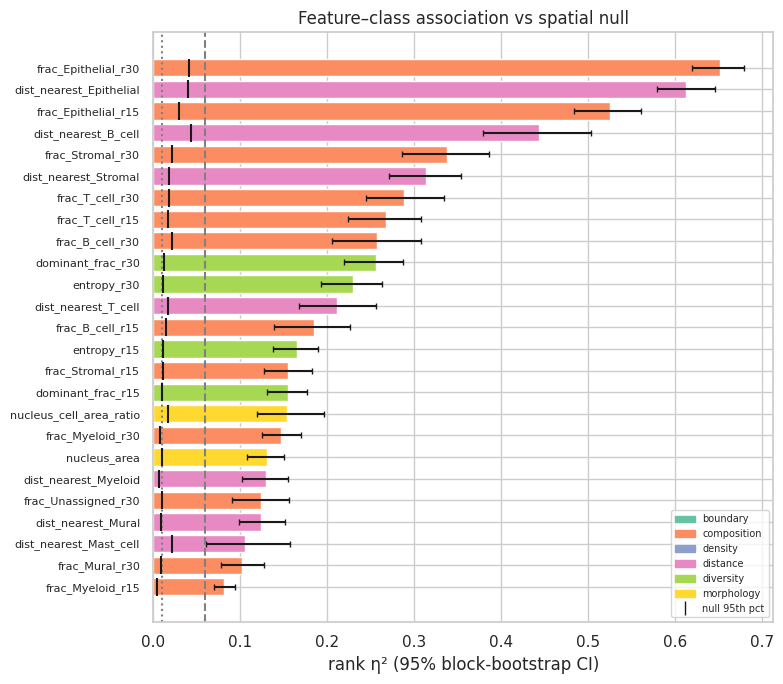

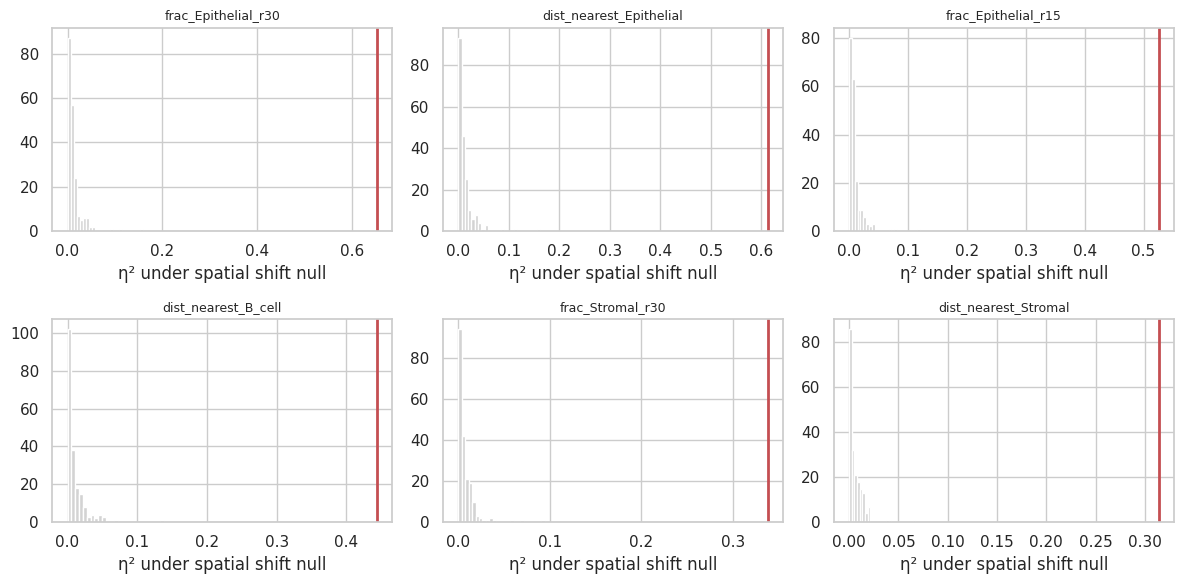

In [8]:
top = res.sort_values("eta2", ascending=False).head(25)
gcol = dict(zip(sorted(res["group"].unique()), sns.color_palette("Set2", n_colors=res["group"].nunique())))

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(top))[::-1]
ax.barh(y, top["eta2"], color=[gcol[g] for g in top["group"]], xerr=[top["eta2"] - top["eta2_ci_low"], top["eta2_ci_high"] - top["eta2"]], ecolor="k", capsize=2)
ax.scatter(top["null_p95_eta2"], y, marker="|", color="k", s=160, zorder=3, label="95th pct of spatial null")
ax.set_yticks(y); ax.set_yticklabels(top["feature"], fontsize=8)
ax.axvline(N4["min_effect_eta2"], color="grey", ls=":"); ax.axvline(N4["medium_effect_eta2"], color="grey", ls="--")
ax.set_xlabel("rank η² (95% block-bootstrap CI)"); ax.set_title("Feature–class association vs spatial null")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in gcol.values()] + [plt.Line2D([], [], marker="|", color="k", ls="", ms=10)],
          labels=list(gcol) + ["null 95th pct"], fontsize=7, loc="lower right")
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_eta2_vs_null.png", dpi=200); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (_, r) in zip(axes.ravel(), res.sort_values("eta2", ascending=False).head(6).iterrows()):
    j = FEATURES.index(r["feature"])
    ax.hist(null_eta[:, j], bins=25, color="lightgrey"); ax.axvline(r["eta2"], color="C3", lw=2)
    ax.set_title(r["feature"], fontsize=9); ax.set_xlabel("η² under spatial shift null")
plt.tight_layout(); fig.savefig(FIG_DIR / "spatial_null_distributions.png", dpi=200); plt.show()

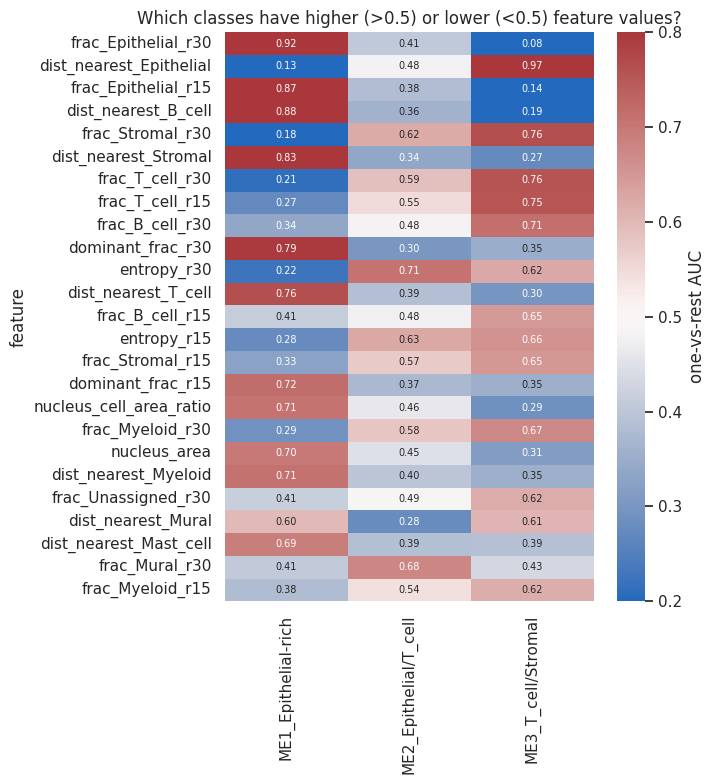

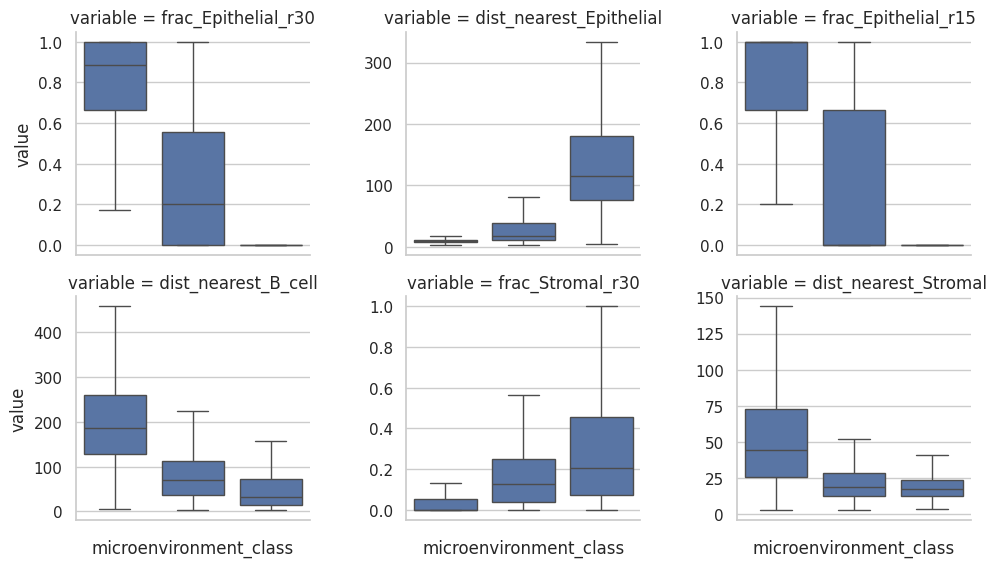

In [9]:
# Class-specific direction: which classes have higher / lower values? (one-vs-rest AUC, 0.5 = no difference)
top_f = res.sort_values("eta2", ascending=False)["feature"].head(25).tolist()
A = res.set_index("feature").loc[top_f, [f"AUC_{c}" for c in CLASSES]]; A.columns = CLASSES
fig, ax = plt.subplots(figsize=(1.4 * K + 3, 8))
sns.heatmap(A, cmap="vlag", center=0.5, vmin=0.2, vmax=0.8, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "one-vs-rest AUC"})
ax.set_title("Which classes have higher (>0.5) or lower (<0.5) feature values?"); plt.tight_layout()
fig.savefig(FIG_DIR / "feature_class_auc_heatmap.png", dpi=200); plt.show()

# Raw distributions of the top features per class (subsample)
ss = T.loc[valid].sample(min(40000, valid.sum()), random_state=SEED)
long = ss[top_f[:6] + ["microenvironment_class"]].melt(id_vars="microenvironment_class")
g = sns.catplot(data=long, x="microenvironment_class", y="value", col="variable", col_wrap=3, kind="box", showfliers=False,
                sharey=False, height=3, aspect=1.1, order=CLASSES)
g.set_xticklabels(rotation=30, ha="right", fontsize=7); g.savefig(FIG_DIR / "top_feature_boxplots.png", dpi=200); plt.show()

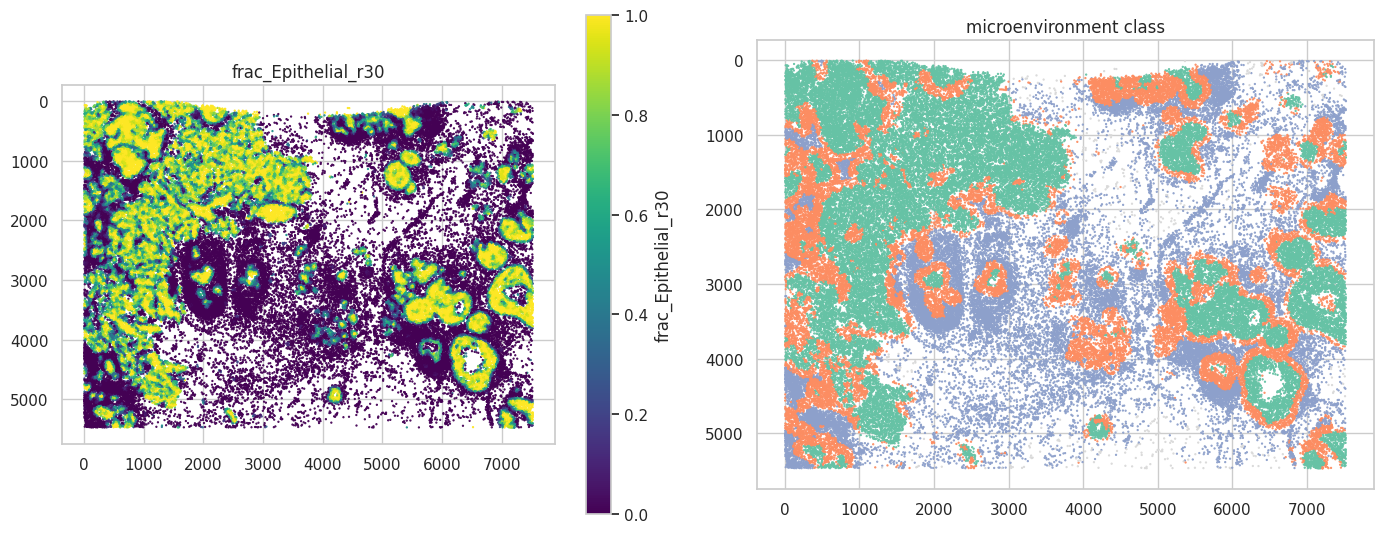

In [10]:
# Spatial view: a top feature next to the class map (downsampled for speed)
f_show = top_f[0]; sh = RNG.choice(len(T), min(80000, len(T)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sc0 = axes[0].scatter(xy[sh, 0], xy[sh, 1], c=T[f_show].to_numpy()[sh], s=0.4, cmap="viridis", rasterized=True)
plt.colorbar(sc0, ax=axes[0], label=f_show); axes[0].set_title(f_show)
pal = dict(zip(CLASSES, sns.color_palette("Set2", n_colors=K)))
cc = [pal.get(v, (0.85, 0.85, 0.85)) for v in T["microenvironment_class"].to_numpy()[sh]]
axes[1].scatter(xy[sh, 0], xy[sh, 1], c=cc, s=0.4, rasterized=True); axes[1].set_title("microenvironment class")
for ax in axes: ax.set_aspect("equal"); ax.invert_yaxis()
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_vs_class_map.png", dpi=200); plt.show()

## Part 6 — Is the neighborhood informative beyond the cell's own type?
A cell's own type already says a lot about its microenvironment (Notebook 03: own-type baseline ≈ 0.62 balanced accuracy). Here we repeat the test **within** each own cell type, so any remaining association is not explained by what the cell itself is. CIs use the block bootstrap; ranks are recomputed inside each type.

,n_cells,median_eta2,max_eta2,n_features_ci_above_negligible
own_type,,,,
Epithelial,69176,0.0131,0.2245,18
Myeloid,15073,0.0227,0.6632,22
Stromal,25852,0.0504,0.6288,30
T_cell,28277,0.0288,0.5652,22


Overall median eta2 across features: 0.1236


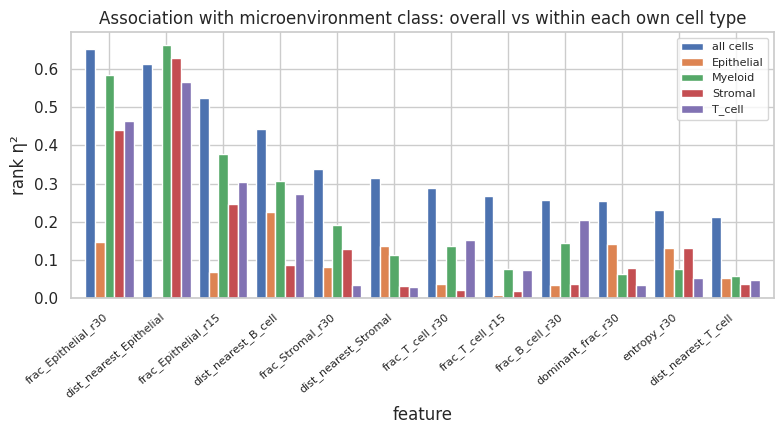

In [11]:
cond_rows = []
for t in ["Epithelial", "T_cell", "Stromal", "Myeloid"]:
    m = valid & (T["cell_type"].to_numpy() == t)
    if m.sum() < N4["conditional_min_cells"]: continue
    ytc = np.bincount(lab[m], minlength=K)
    if (ytc >= 100).sum() < 2: continue
    Ft = T.loc[m, FEATURES]
    # a feature that is constant inside the type (e.g. NaN-only) is dropped by NaN handling in rank_matrix
    Pt, Mt = st.rank_matrix(Ft)
    bc, bu = pd.factorize(T.loc[m, "spatial_block"])
    lt = lab[m].copy(); lt[np.isin(lt, np.where(ytc < 100)[0])] = -1          # ignore tiny classes inside the type
    Sb, Nb, Qb = st.group_sums(Pt, Mt, lt, K, group=bc, n_groups=len(bu))
    e = st.eta2_from_sums(Sb.sum(0), Nb.sum(0), Qb.sum(0))
    ebs, _ = st.block_bootstrap(Sb, Nb, Qb, N4["conditional_bootstrap"], RNG)
    lo, hi = np.nanpercentile(ebs, [2.5, 97.5], axis=0)
    for j, f in enumerate(FEATURES):
        cond_rows.append({"own_type": t, "feature": f, "group": GROUP[f], "eta2": e[j], "ci_low": lo[j], "ci_high": hi[j], "n_cells": int(m.sum())})
cond = pd.DataFrame(cond_rows)
cond.round(6).to_csv(TAB_DIR / "feature_class_association_within_cell_type.csv", index=False)

summ = cond.groupby("own_type").agg(n_cells=("n_cells", "first"), median_eta2=("eta2", "median"), max_eta2=("eta2", "max"),
                                    n_features_ci_above_negligible=("ci_low", lambda s: int((s >= N4["min_effect_eta2"]).sum())))
display(summ.round(4))
print("Overall median eta2 across features: %.4f" % res["eta2"].median())

pv = cond[cond["feature"].isin(top_f[:12])].pivot(index="feature", columns="own_type", values="eta2").reindex(top_f[:12])
pv.insert(0, "all cells", res.set_index("feature").loc[top_f[:12], "eta2"])
fig, ax = plt.subplots(figsize=(8, 4.5)); pv.plot.bar(ax=ax, width=0.85); ax.set_ylabel("rank η²")
ax.set_title("Association with microenvironment class: overall vs within each own cell type"); ax.legend(fontsize=8)
plt.xticks(rotation=40, ha="right", fontsize=8); plt.tight_layout(); fig.savefig(FIG_DIR / "eta2_within_cell_type.png", dpi=200); plt.show()

## Part 7 — Neighborhood enrichment against two null models
For every pair of cell types we count how many pairs of cells lie within 15 µm (and 30 µm), and compare with:

* **Global null** — cell-type labels shuffled across the whole section. Rejecting it only shows that cell types are not randomly mixed, which is trivially true for tissue (tumor and stroma occupy different regions).
* **Within-tile null (stricter)** — labels shuffled only inside 250 µm tiles. Rejecting it means the pair is enriched or avoided **at the local scale, beyond regional composition**.

Results are `log2(observed / null mean)`; `*` marks BH-adjusted q < 0.05 (two-sided empirical p).

In [12]:
tree = cKDTree(xy)
r_max = max(N4["enrichment_radii_um"])
pairs = tree.query_pairs(r=r_max, output_type="ndarray")
pi, pj = pairs[:, 0], pairs[:, 1]
pd_ = np.hypot(xy[pi, 0] - xy[pj, 0], xy[pi, 1] - xy[pj, 1])
print(f"Unordered cell pairs within {r_max} µm: {len(pi):,}")

tile = (np.floor((xy[:, 0] - xy[:, 0].min()) / N4["null_tile_um"]).astype(np.int64) * 100000
        + np.floor((xy[:, 1] - xy[:, 1].min()) / N4["null_tile_um"]).astype(np.int64))
Tn = len(ALL_TYPES); Bp = N4["n_label_permutations"]; U = Tn - 1                      # last code = Unassigned
iu = np.triu_indices(Tn)
keep_pairs = [(a, b) for a, b in zip(*iu) if a < U and b < U]

enrich = []
for r in N4["enrichment_radii_um"]:
    m = pd_ <= r; ii, jj = pi[m], pj[m]
    obs_c = st.pair_counts(codes[ii], codes[jj], Tn)
    for null_name in ["global", "within_tile"]:
        null_c = np.zeros((Bp, Tn, Tn))
        for b in range(Bp):
            cp = RNG.permutation(codes) if null_name == "global" else st.within_group_permutation(codes, tile, RNG)
            null_c[b] = st.pair_counts(cp[ii], cp[jj], Tn)
        for a, bb in keep_pairs:
            nv = null_c[:, a, bb]; ov = obs_c[a, bb]
            mu, sd = nv.mean(), nv.std()
            p = (1 + np.sum(np.abs(nv - mu) >= abs(ov - mu))) / (Bp + 1)
            enrich.append({"radius_um": r, "null": null_name, "type_a": ALL_TYPES[a], "type_b": ALL_TYPES[bb],
                           "observed": int(ov), "null_mean": mu, "log2_obs_over_null": np.log2((ov + 1) / (mu + 1)),
                           "z": (ov - mu) / sd if sd > 0 else np.nan, "p": p})
E = pd.DataFrame(enrich)
E["q"] = E.groupby(["radius_um", "null"])["p"].transform(lambda s: pd.Series(st.benjamini_hochberg(s.to_numpy()), index=s.index))
E.round(5).to_csv(TAB_DIR / "neighborhood_enrichment.csv", index=False)
print("Done:", len(E), "pair tests")

Unordered cell pairs within 30 µm: 1,510,938
Done: 144 pair tests


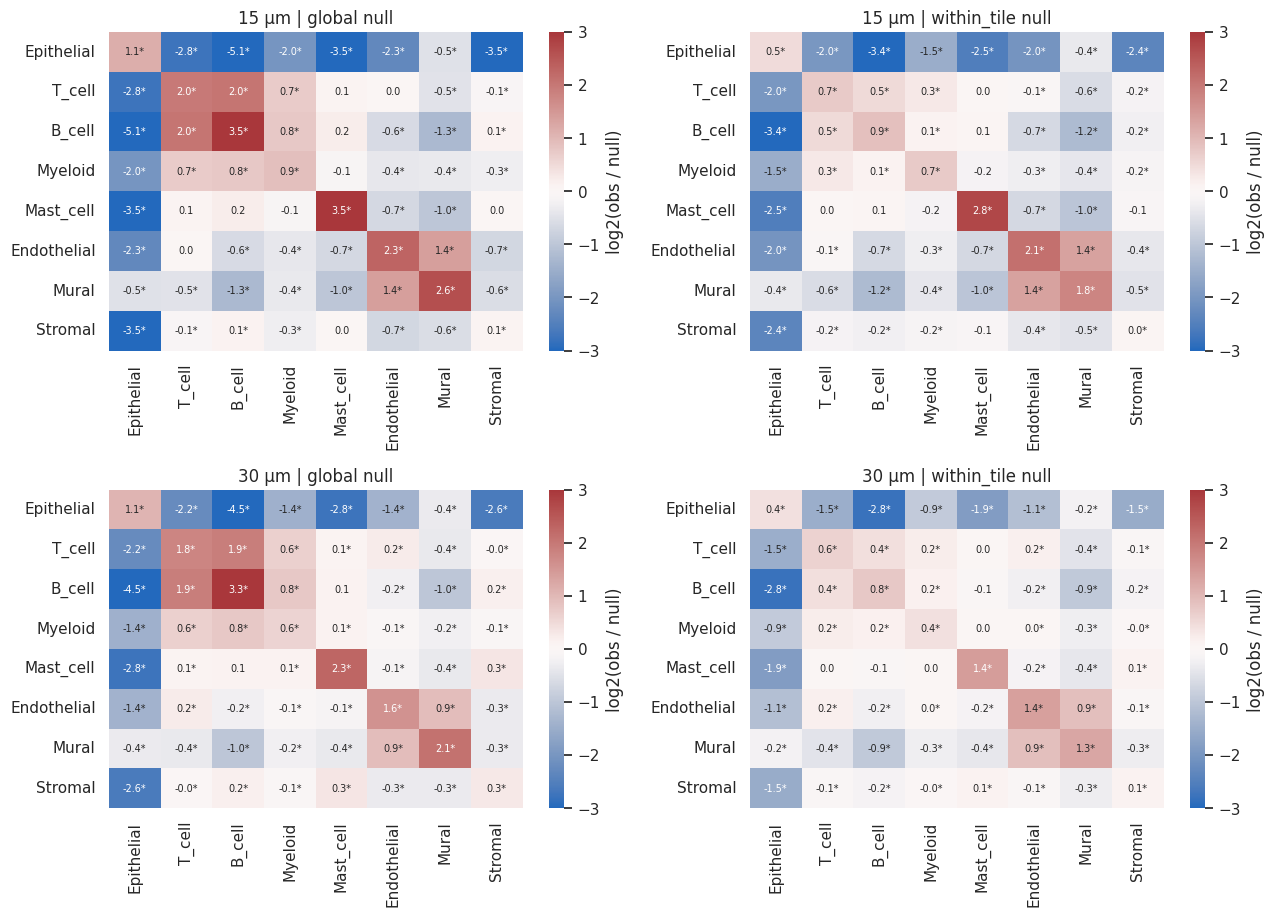

Significant under global null: 66/72 | surviving the within-tile null: 65/72
Pairs whose enrichment is explained by regional composition (lost under within-tile null):


,radius_um,type_a,type_b,log2_obs_over_null_global,log2_obs_over_null_within_tile,q_global,q_within_tile
67,30,T_cell,Mast_cell,0.112,0.033,0.006,0.418
60,30,Myeloid,Mast_cell,0.124,0.041,0.016,0.389


Strongest local-scale enrichments / avoidances (within-tile null):


,radius_um,type_a,type_b,log2_obs_over_null_global,log2_obs_over_null_within_tile,q_global,q_within_tile
9,15,Epithelial,B_cell,-5.066,-3.370,0.006,0.006
45,30,Epithelial,B_cell,-4.476,-2.792,0.006,0.006
18,15,Mast_cell,Mast_cell,3.535,2.763,0.006,0.006
12,15,Epithelial,Mast_cell,-3.477,-2.545,0.006,0.006
15,15,Epithelial,Stromal,-3.500,-2.373,0.006,0.006
6,15,Endothelial,Endothelial,2.318,2.124,0.006,0.006
10,15,Epithelial,Endothelial,-2.309,-2.046,0.006,0.006
16,15,Epithelial,T_cell,-2.754,-1.983,0.006,0.006
48,30,Epithelial,Mast_cell,-2.756,-1.858,0.006,0.006
21,15,Mural,Mural,2.634,1.800,0.006,0.006


In [13]:
radii_e = N4["enrichment_radii_um"]
fig, axes = plt.subplots(len(radii_e), 2, figsize=(13, 5.6 * len(radii_e) / 1.2))
axes = np.atleast_2d(axes)
for ri, r in enumerate(radii_e):
    for ci, nn in enumerate(["global", "within_tile"]):
        d = E[(E["radius_um"] == r) & (E["null"] == nn)]
        L = d.pivot(index="type_a", columns="type_b", values="log2_obs_over_null").reindex(index=TYPES, columns=TYPES)
        Qm = d.pivot(index="type_a", columns="type_b", values="q").reindex(index=TYPES, columns=TYPES)
        Lf = L.combine_first(L.T); Qf = Qm.combine_first(Qm.T)
        ann_ = Lf.round(1).astype(str) + np.where(Qf < N4["fdr_alpha"], "*", "")
        sns.heatmap(Lf, cmap="vlag", center=0, vmin=-3, vmax=3, annot=ann_, fmt="", annot_kws={"size": 7}, ax=axes[ri, ci],
                    cbar_kws={"label": "log2(obs / null)"})
        axes[ri, ci].set_title(f"{r} µm | {nn} null"); axes[ri, ci].set_xlabel(""); axes[ri, ci].set_ylabel("")
plt.tight_layout(); fig.savefig(FIG_DIR / "neighborhood_enrichment_heatmaps.png", dpi=200); plt.show()

# Which pairs are significant under the global null but NOT under the stricter within-tile null?
w = E.pivot_table(index=["radius_um", "type_a", "type_b"], columns="null", values=["q", "log2_obs_over_null"])
w.columns = ["_".join(c) for c in w.columns]; w = w.reset_index()
lost = w[(w["q_global"] < N4["fdr_alpha"]) & (w["q_within_tile"] >= N4["fdr_alpha"])]
kept = w[(w["q_within_tile"] < N4["fdr_alpha"])]
print(f"Significant under global null: {(w['q_global'] < N4['fdr_alpha']).sum()}/{len(w)} | surviving the within-tile null: {len(kept)}/{len(w)}")
print("Pairs whose enrichment is explained by regional composition (lost under within-tile null):")
display(lost.sort_values("log2_obs_over_null_global").round(3).head(12))
print("Strongest local-scale enrichments / avoidances (within-tile null):")
display(kept.reindex(kept["log2_obs_over_null_within_tile"].abs().sort_values(ascending=False).index).round(3).head(12))

## Part 8 — Summary and saved results

In [14]:
sup = res[res["supported"]].sort_values("eta2", ascending=False)
neg_ctrl = res[res["group"] == "morphology"]
print("=== Key results (auto-generated; check against the figures) ===")
print(f"1. {len(sup)}/{len(res)} features show class association above the spatial null with a CI above 'negligible'.")
for g_, d in res.groupby("group"):
    print(f"   - {g_:12s} mean eta2 = {d['eta2'].mean():.3f} (max {d['eta2'].max():.3f}); supported {int(d['supported'].sum())}/{len(d)}")
print(f"2. Morphology (cell-intrinsic control group): mean eta2 = {neg_ctrl['eta2'].mean():.3f}; supported {int(neg_ctrl['supported'].sum())}/{len(neg_ctrl)}.")
best = res.sort_values("eta2", ascending=False).iloc[0]
print(f"3. Strongest feature: {best['feature']} (eta2 {best['eta2']:.3f}, 95% CI {best['eta2_ci_low']:.3f}-{best['eta2_ci_high']:.3f}; spatial-null p {best['p_spatial_null']:.3f}).")
print(f"4. Naive KW p<1e-6 for {(res['naive_KW_p']<1e-6).sum()}/{len(res)} features, but only {len(sup)} are supported under spatial nulls.")
if len(cond):
    print("5. Within own cell type, median eta2 by type:", cond.groupby('own_type')['eta2'].median().round(3).to_dict(), "(overall median %.3f)" % res['eta2'].median())
print(f"6. Local enrichment surviving the within-tile null: {len(kept)}/{len(w)} pair tests.")

report = {
    "n_cells_analysed": int(valid.sum()), "classes": CLASSES, "n_blocks": int(nb),
    "n_features": int(len(res)), "n_features_supported": int(res["supported"].sum()),
    "supported_features": sup["feature"].tolist(),
    "naive_p_below_1e-6": int((res["naive_KW_p"] < 1e-6).sum()),
    "morphology_control_mean_eta2": float(neg_ctrl["eta2"].mean()),
    "target_label_reproduction": float(reproduced), "low_margin_threshold": float(low_margin_cut),
    "enrichment_survive_within_tile_null": [int(len(kept)), int(len(w))],
    "settings": N4,
}
json.dump(report, open(REP_DIR / "notebook_04_report.json", "w"), indent=2)
CONFIG["notebook04"] = N4
json.dump(CONFIG, open(PROJECT_DIR / "configs/config.json", "w"), indent=2)
print("\nSaved: feature_class_association_results.csv, ..._within_cell_type.csv, neighborhood_enrichment.csv, target_reliability.csv, notebook_04_report.json")

=== Key results (auto-generated; check against the figures) ===
1. 31/43 features show class association above the spatial null with a CI above 'negligible'.
   - boundary     mean eta2 = 0.030 (max 0.056); supported 1/2
   - composition  mean eta2 = 0.184 (max 0.652); supported 16/18
   - density      mean eta2 = 0.010 (max 0.012); supported 0/4
   - distance     mean eta2 = 0.168 (max 0.613); supported 8/12
   - diversity    mean eta2 = 0.201 (max 0.256); supported 4/4
   - morphology   mean eta2 = 0.098 (max 0.154); supported 2/3
2. Morphology (cell-intrinsic control group): mean eta2 = 0.098; supported 2/3.
3. Strongest feature: frac_Epithelial_r30 (eta2 0.652, 95% CI 0.620-0.679; spatial-null p 0.005).
4. Naive KW p<1e-6 for 43/43 features, but only 31 are supported under spatial nulls.
5. Within own cell type, median eta2 by type: {'Epithelial': 0.013, 'Myeloid': 0.023, 'Stromal': 0.05, 'T_cell': 0.029} (overall median 0.124)
6. Local enrichment surviving the within-tile null: 65

## Reading the results (what you can and cannot claim)
* **Supported** means: association above a spatial null at FDR 5% **and** a block-bootstrap CI above the negligible threshold (η² ≥ 0.01). It is evidence of association, not causation or of a predictive gain.
* The target is derived from **cell-type composition at 50–100 µm**, and several features are composition at ≤ 30 µm. Spatial autocorrelation makes some association unavoidable; the shift null shows how much exceeds that baseline.
* All tests come from **one tissue section**. Blocks are not independent biological replicates; generalisation to other patients is untested.
* Cell-type labels are marker-based and expression-derived (see Notebook 02 limitations).
* The minimum empirical p-value is 1/(B+1). Increase `n_shift_null` if many features sit at the floor.

## Checklist before Notebook 05 (ML baselines)
- [ ] Unit tests passed (η² = Kruskal–Wallis, AUC = sklearn)
- [ ] `target_continuum.png`: you understand how much of the target is boundary cells
- [ ] Which feature groups beat the spatial null? Morphology should be weak (negative control)
- [ ] Within-own-type η² > 0 for at least some features means the neighborhood adds information beyond cell identity
- [ ] The enrichment table separates "regional composition" from "local-scale" structure